In [ ]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.stats import boxcox, kstest, norm
from scipy.stats import boxcox_normmax
from matplotlib.ticker import MaxNLocator
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.diagnostic import het_arch
from scipy.special import inv_boxcox
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import math
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from lightgbm import LGBMRegressor
from itertools import product
import warnings
warnings.filterwarnings('ignore')

# Format sumbu Y jadi Rupiah; beri ruang kalau garisnya datar
def rapikan_sumbu_y(ax, *deret):
    semua = np.concatenate([np.asarray(d, dtype=float).ravel() for d in deret])
    if semua.max() - semua.min() < 0.01 * semua.mean():
        ax.set_ylim(semua.mean() * 0.9, semua.mean() * 1.1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

In [3]:
# Cek jumlah data kosong per kolom
print(df.isna().sum())

Tanggal           0
Pasar Genteng     0
Pasar Keputran    0
dtype: int64


In [ ]:
# Isi harga kosong di tengah (interpolasi), buang baris kosong di ujung data
df = df.set_index('Tanggal')
jumlah_awal = len(df)
df = df.interpolate(method='linear', limit_area='inside')
df = df.dropna()
baris_dipangkas = jumlah_awal - len(df)
print(df.isna().sum())
print(f'Baris di ujung data yang dibuang: {baris_dipangkas}')

In [5]:
# Statistik ringkas data
df.describe()

,Pasar Genteng,Pasar Keputran
count,1946.000000,1946.000000
mean,47809.866393,47015.930113
std,24098.380734,22494.312405
min,15000.000000,15000.000000
25%,30000.000000,30000.000000
50%,40000.000000,40000.000000
75%,60000.000000,60000.000000
max,140000.000000,120000.000000


In [ ]:
# Plot harga historis tiap pasar
pasar_list = df.columns.tolist()
colors     = ['#3A86FF', '#9B5DE5', '#E63946', '#2A9D8F', '#F4A261', '#264653']

plt.figure(figsize=(8, 4 * len(pasar_list)))

for i, pasar in enumerate(pasar_list):
    plt.subplot(len(pasar_list), 1, i + 1)
    plt.plot(df.index, df[pasar], linewidth=1.1, color=colors[i], label=pasar)
    plt.title(pasar)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.ylabel('Harga (Rp)')
    plt.xticks(rotation=30)
    plt.grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Harga Cabai Rawit Merah - Pasar Surabaya', fontsize=13, fontweight='bold')
plt.tight_layout(pad=2.0)
plt.show()

In [7]:
# Split data: 14 hari terakhir = test, sisanya train
N_TEST = 14
datasets_raw = {}
split_rows = []

for pasar in pasar_list:
    series = df[pasar].dropna()
    train = series.iloc[:-N_TEST]
    test = series.iloc[-N_TEST:]
    datasets_raw[pasar] = {'train': train, 'test': test, 'full': series}

    split_rows.append({
        'Jenis Pembagian': 'Data Train' if pasar == pasar_list[0] else None,
        'Pasar': pasar,
        'Periode': f"{train.index.min().strftime('%d %B %Y')} – {train.index.max().strftime('%d %B %Y')}",
        'Jumlah Data': len(train)
    })
    split_rows.append({
        'Jenis Pembagian': 'Data Test' if pasar == pasar_list[0] else None,
        'Pasar': pasar,
        'Periode': f"{test.index.min().strftime('%d %B %Y')} – {test.index.max().strftime('%d %B %Y')}",
        'Jumlah Data': len(test)
    })

split_summary_df = pd.DataFrame(split_rows)
# Tabel ringkas periode & jumlah data train/test
split_table_df = pd.DataFrame([
    {
        'Jenis Pembagian': 'Data Train',
        'Periode': f"{datasets_raw[pasar_list[0]]['train'].index.min().strftime('%d %B %Y')} – {datasets_raw[pasar_list[0]]['train'].index.max().strftime('%d %B %Y')}",
        'Jumlah Data': len(datasets_raw[pasar_list[0]]['train'])
    },
    {
        'Jenis Pembagian': 'Data Test',
        'Periode': f"{datasets_raw[pasar_list[0]]['test'].index.min().strftime('%d %B %Y')} – {datasets_raw[pasar_list[0]]['test'].index.max().strftime('%d %B %Y')}",
        'Jumlah Data': len(datasets_raw[pasar_list[0]]['test'])
    },
])

display(split_table_df)

Pasar Genteng: total=1946, train=1932, test=14
  Train: 2021-01-01 s.d. 2026-04-16
  Test : 2026-04-17 s.d. 2026-04-30

Pasar Keputran: total=1946, train=1932, test=14
  Train: 2021-01-01 s.d. 2026-04-16
  Test : 2026-04-17 s.d. 2026-04-30



In [ ]:
# Uji stasioner varians (Box-Cox) pada data train
boxcox_lambdas = {}
df_transformed = pd.DataFrame(index=df.index)
datasets = {}
boxcox_rows = []

for pasar in pasar_list:
    train = datasets_raw[pasar]['train'].astype(float)
    test = datasets_raw[pasar]['test'].astype(float)
    full = datasets_raw[pasar]['full'].astype(float)

    _, lam_estimasi = boxcox(train.values)
    rounded_value = round(lam_estimasi)

    # Rounded lambda = 1 -> tidak perlu transformasi
    lam = lam_estimasi if rounded_value != 1 else 1.0
    train_bc_values = boxcox(train.values, lmbda=lam)
    train_bc = pd.Series(train_bc_values, index=train.index, name=pasar)

    boxcox_lambdas[pasar] = lam
    df_transformed.loc[train.index, pasar] = train_bc

    datasets[pasar] = {
        'train': train_bc,
        'test': test,
        'full': full
    }

    boxcox_rows.append({
        'Pasar': pasar,
        'Lambda Awal': lam_estimasi,
        'Rounded Lambda': rounded_value,
        'Keputusan': 'Tidak perlu transformasi' if rounded_value == 1 else 'Perlu transformasi Box-Cox'
    })

boxcox_summary_df = pd.DataFrame(boxcox_rows)
display(boxcox_summary_df[['Pasar', 'Lambda Awal', 'Keputusan']])

# Judul plot menyesuaikan pasar yang ditransformasi
pasar_ditransformasi = [p for p in pasar_list if round(boxcox_lambdas[p]) != 1]
if not pasar_ditransformasi:
    judul_plot = 'Data Train Setelah Uji Stasioner Varians (Tanpa Transformasi Box-Cox)'
elif len(pasar_ditransformasi) == len(pasar_list):
    judul_plot = 'Hasil Transformasi Box-Cox Data Train'
else:
    judul_plot = 'Data Train Setelah Uji Stasioner Varians (Sebagian Ditransformasi Box-Cox)'

# Plot data train setelah uji varians
fig, axes = plt.subplots(1, len(pasar_list), figsize=(13, 4.5), squeeze=False)
for i, pasar in enumerate(pasar_list):
    ax = axes[0, i]
    train_bc = datasets[pasar]['train']
    perlu_transformasi = round(boxcox_lambdas[pasar]) != 1
    ax.plot(train_bc.index, train_bc, color=colors[i], linewidth=0.9)
    ax.set_title(pasar, fontweight='bold')
    ax.set_ylabel('Nilai Transformasi' if perlu_transformasi else 'Harga (Rp), tanpa transformasi')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    jumlah_bulan = (train_bc.index.max() - train_bc.index.min()).days / 30
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=max(1, int(jumlah_bulan / 8))))
    ax.tick_params(axis='x', rotation=30)
    ax.grid(True, linestyle='--', alpha=0.4)
fig.suptitle(judul_plot, fontsize=13, fontweight='bold')
fig.tight_layout(pad=2.0)
plt.show()

In [ ]:
# Uji stasioner mean: ADF + pola ACF (keduanya harus terpenuhi)
alpha = 0.05
N_LAG_ACF = 20
BATAS_ACF_LAMBAT = 0.5

def cek_stasioner_mean(seri):
    adf_stat, p_val, _, _, _, _ = adfuller(seri, autolag='AIC')

    nilai_acf = acf(seri, nlags=N_LAG_ACF)[1:]
    batas = 1.96 / np.sqrt(len(seri))
    persen_di_luar_batas = np.mean(np.abs(nilai_acf) > batas) * 100

    # ADF: p < 0,05 | ACF: maksimal 50% lag di luar batas
    adf_ok = p_val < alpha
    acf_ok = persen_di_luar_batas <= BATAS_ACF_LAMBAT * 100
    return adf_stat, p_val, persen_di_luar_batas, adf_ok, acf_ok

# Hasil uji sebelum differencing
adf_before_rows = []
for pasar in pasar_list:
    train = datasets[pasar]['train'].dropna()
    adf_stat, p_val, persen_acf, adf_ok, acf_ok = cek_stasioner_mean(train)
    adf_before_rows.append({
        'Pasar': pasar,
        'ADF Statistic': adf_stat,
        'P-value': p_val,
        'ACF di Luar Batas (%)': persen_acf,
        'Keputusan': 'Stasioner' if (adf_ok and acf_ok) else 'Tidak stasioner'
    })

adf_before_df = pd.DataFrame(adf_before_rows)
display(adf_before_df)

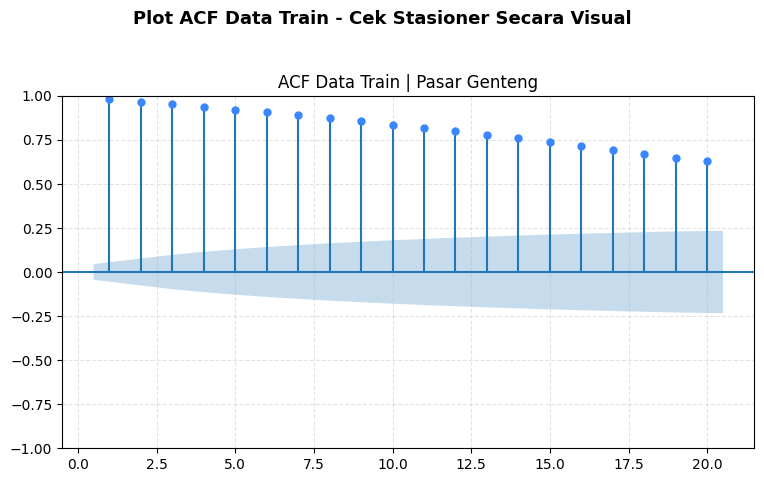

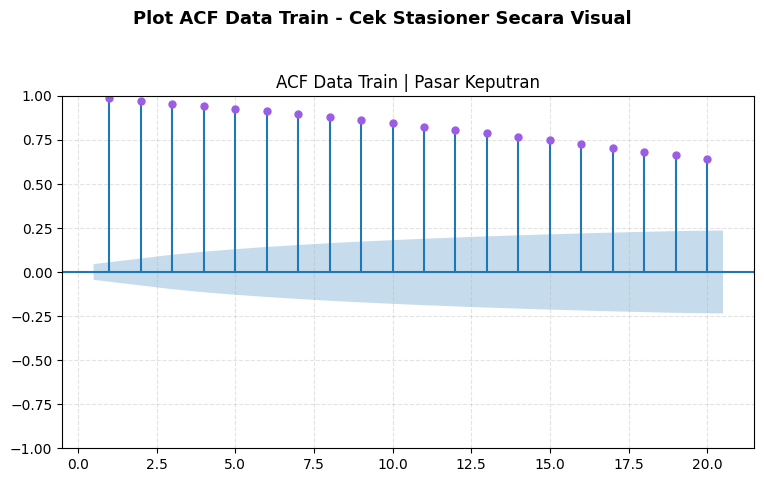

In [10]:
# Plot ACF data train
fig, axes = plt.subplots(1, len(pasar_list), figsize=(13, 4.5), squeeze=False)
for i, pasar in enumerate(pasar_list):
    train = datasets[pasar]['train'].dropna()
    ax = axes[0, i]
    plot_acf(train, lags=20, ax=ax, title=f'ACF Data Train | {pasar}', zero=False, alpha=0.05)
    for line in ax.lines[1:]:
        line.set_color(colors[i])
    ax.grid(True, linestyle='--', alpha=0.35)
fig.suptitle('Plot ACF Data Train - Cek Stasioner Secara Visual', fontsize=13, fontweight='bold')
fig.tight_layout(pad=2.0)
plt.show()

In [ ]:
# Differencing berulang sampai stasioner (maks 2 kali) -> nilai d
MAKS_D = 2
diff_results = {}
d_terpilih = {}
diff_log_rows = []

for pasar in pasar_list:
    seri = datasets[pasar]['train'].dropna()
    d = 0

    while True:
        adf_stat, p_val, persen_acf, adf_ok, acf_ok = cek_stasioner_mean(seri)

        alasan = []
        if not adf_ok:
            alasan.append('ADF belum stasioner')
        if not acf_ok:
            alasan.append('ACF meluruh lambat')

        diff_log_rows.append({
            'Pasar': pasar,
            'Differencing (d)': d,
            'P-value ADF': p_val,
            'ACF di Luar Batas (%)': persen_acf,
            'Keputusan': 'Stasioner' if (adf_ok and acf_ok) else 'Tidak stasioner',
            'Keterangan': ', '.join(alasan) if alasan else 'ADF dan ACF terpenuhi'
        })

        # Berhenti kalau sudah stasioner atau d sudah maksimal
        if (adf_ok and acf_ok) or d >= MAKS_D:
            break

        seri = seri.diff(1).dropna()
        d += 1

    d_terpilih[pasar] = d
    diff_results[pasar] = {'d': d, 'seri_diff': seri}

diff_log_df = pd.DataFrame(diff_log_rows)
display(diff_log_df)

d_unik = sorted(set(d_terpilih.values()) - {0})
label_diff = f'Diff({d_unik[0]})' if len(d_unik) == 1 else 'Diff(d)'

# Tabel ringkas p-value ADF sebelum & sesudah differencing
adf_compare_rows = []
for pasar in pasar_list:
    baris = diff_log_df[diff_log_df['Pasar'] == pasar]
    awal = baris.iloc[0]
    akhir = baris.iloc[-1]
    ada_diff = d_terpilih[pasar] > 0

    adf_compare_rows.append({
        'Pasar': pasar,
        'P-value Sebelum Diff': awal['P-value ADF'],
        'Keputusan Sebelum Diff': 'Stasioner' if awal['P-value ADF'] < alpha else 'Tidak stasioner',
        f'P-value Setelah {label_diff}': akhir['P-value ADF'] if ada_diff else np.nan,
        f'Keputusan Setelah {label_diff}': ('Stasioner' if akhir['P-value ADF'] < alpha else 'Tidak stasioner') if ada_diff else '-'
    })

adf_compare_df = pd.DataFrame(adf_compare_rows)
display(adf_compare_df)

In [ ]:
# Plot ACF & PACF data hasil differencing (untuk menentukan p dan q)
for i, pasar in enumerate(pasar_list):
    train_diff = diff_results[pasar]['seri_diff']
    d = diff_results[pasar]['d']

    plt.figure(figsize=(12, 4))
    plt.suptitle(f'Identifikasi Parameter ARIMA - {pasar} (d = {d})', fontsize=13, fontweight='bold')

    plt.subplot(1, 2, 1)
    plot_acf(train_diff, lags=20, ax=plt.gca(), title=f'ACF | {pasar}', zero=False, alpha=0.05, auto_ylims=True)
    for line in plt.gca().lines[1:]: line.set_color(colors[i % len(colors)])
    plt.grid(True, linestyle='--', alpha=0.35)

    plt.subplot(1, 2, 2)
    plot_pacf(train_diff, lags=20, ax=plt.gca(), title=f'PACF | {pasar}', zero=False, alpha=0.05, method='ywm', auto_ylims=True)
    for line in plt.gca().lines[1:]: line.set_color(colors[i % len(colors)])
    plt.grid(True, linestyle='--', alpha=0.35)

    plt.tight_layout()
    plt.show()

In [ ]:
# Estimasi semua kombinasi orde ARIMA, pilih AIC terkecil
# Rentang orde p, d, q dari web; kalau dijalankan manual pakai p, q = 0-1 dan d dari hasil differencing
if 'order_ranges_input' in globals():
    order_ranges = order_ranges_input
else:
    order_ranges = {}
    for pasar in pasar_list:
        order_ranges[pasar] = {'p': (0, 1), 'd': (d_terpilih[pasar], d_terpilih[pasar]), 'q': (0, 1)}

# Susun semua kombinasi (p, d, q)
candidate_orders = {}
for pasar in pasar_list:
    p_min, p_maks = order_ranges[pasar]['p']
    q_min, q_maks = order_ranges[pasar]['q']
    d_min, d_maks = order_ranges[pasar]['d']

    candidate_orders[pasar] = []
    for p in range(p_min, p_maks + 1):
        for d in range(d_min, d_maks + 1):
            for q in range(q_min, q_maks + 1):
                candidate_orders[pasar].append((p, d, q))

best_orders = {}
estimation_results = {}
aic_tables = {}

for pasar in pasar_list:
    train_transformed = datasets[pasar]['train'].dropna()
    results = []

    # Estimasi tiap kandidat dengan MLE
    for order in candidate_orders[pasar]:
        try:
            res = ARIMA(train_transformed, order=order).fit(method='innovations_mle')
            results.append({'order': order, 'aic': res.aic, 'model': res})
        except Exception as e:
            print(f"ARIMA{order} pada {pasar} gagal diestimasi: {e}")

    if not results:
        raise RuntimeError(f"Tidak ada kandidat ARIMA yang berhasil diestimasi untuk {pasar}.")

    results.sort(key=lambda x: x['aic'])
    estimation_results[pasar] = results
    best_orders[pasar] = results[0]['order']
    aic_tables[pasar] = pd.DataFrame([
        {'Orde': f"ARIMA{r['order']}", 'AIC': r['aic']} for r in results
    ])

    print(f"{pasar}: {len(candidate_orders[pasar])} kandidat diuji")
    display(aic_tables[pasar])
    print(f"Model AIC terbaik: ARIMA{best_orders[pasar]}")

In [ ]:
# Model ARIMA final = kandidat dengan AIC terkecil
final_orders = best_orders.copy()
fitted_models = {}

for pasar in pasar_list:
    fitted_models[pasar] = estimation_results[pasar][0]['model']
    print(f"{pasar} - ARIMA{final_orders[pasar]} terpilih (AIC terkecil)")

In [ ]:
# Prediksi ARIMA pada periode test, lalu plot
actuals_dict = {}
forecasts_dict = {}

for pasar in pasar_list:
    lam = boxcox_lambdas[pasar]
    res = fitted_models[pasar]
    actual_rp = datasets[pasar]['test'].astype(float)
    test_idx = actual_rp.index

    forecast_mean = res.get_forecast(steps=N_TEST).predicted_mean
    forecast_mean.index = test_idx

    # Inverse Box-Cox: kembali ke Rupiah
    pred_rp = inv_boxcox(forecast_mean.values, lam)

    actuals_dict[pasar] = actual_rp.values
    forecasts_dict[pasar] = pred_rp

    plt.figure(figsize=(10, 5))
    plt.plot(test_idx, actual_rp.values, color='#2E86AB', linestyle='-', linewidth=1.8, marker='o', markersize=4, label='Aktual')
    plt.plot(test_idx, pred_rp, color='#ff7f0e', linestyle='--', linewidth=1.8, marker='^', markersize=4, label='Prediksi')
    plt.title(f'{pasar} [ARIMA{final_orders[pasar]}] - Prediksi vs Aktual', fontsize=11, fontweight='bold')
    plt.ylabel('Harga (Rp)', fontsize=9)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
    plt.legend(fontsize=8, framealpha=0.6)
    rapikan_sumbu_y(plt.gca(), actual_rp.values, pred_rp)
    plt.grid(True, linestyle='--', alpha=0.35)
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout(pad=2.0)
    plt.show()

In [17]:
# Evaluasi ARIMA: RMSE, MAE, MAPE
arima_eval_rows = []
for pasar in pasar_list:
    actual = actuals_dict[pasar]
    pred = forecasts_dict[pasar]
    arima_eval_rows.append({
        'Pasar': pasar,
        'RMSE (Rp)': root_mean_squared_error(actual, pred),
        'MAE (Rp)': mean_absolute_error(actual, pred),
        'MAPE (%)': mean_absolute_percentage_error(actual, pred) * 100
    })

arima_eval_df = pd.DataFrame(arima_eval_rows)
display(arima_eval_df)

Pasar                       RMSE (Rp)       MAE (Rp)   MAPE (%)
----------------------------------------------------------------
Pasar Genteng               12,379.57      10,645.27     23.23
Pasar Keputran              13,363.06      12,142.86     24.39


In [26]:
# Uji asumsi residual ARIMA
alpha = 0.05
assumption_rows = []

for pasar in pasar_list:
    burn = fitted_models[pasar].loglikelihood_burn
    residuals = fitted_models[pasar].resid.iloc[burn:].dropna()

    # Normalitas (Kolmogorov-Smirnov)
    res_std = (residuals - residuals.mean()) / residuals.std()
    ks_stat, ks_pval = kstest(res_std, 'norm')

    # Autokorelasi / white noise (Ljung-Box)
    lb_result = acorr_ljungbox(residuals, lags=[10, 20], return_df=True)
    lb_pval_min = lb_result['lb_pvalue'].min()

    # Kestabilan varians residual (ARCH-LM)
    arch_lm_stat = het_arch(residuals, nlags=7)
    arch_pval = arch_lm_stat[1]

    assumption_rows.append({
        'Pasar': pasar,
        'KS p-value': ks_pval,
        'KS': 'Gagal Tolak H0' if ks_pval >= alpha else 'Tolak H0',
        'Ljung-Box p-value': lb_pval_min,
        'Ljung-Box': 'White noise' if lb_pval_min >= alpha else 'Tidak white noise',
        'ARCH-LM p-value': arch_pval,
        'ARCH-LM': 'Homoskedastis' if arch_pval >= alpha else 'Heteroskedastis'
    })

assumption_results_df = pd.DataFrame(assumption_rows)
display(assumption_results_df)


-------------------------------------------------------
  Pasar Genteng
-------------------------------------------------------

[13a] UJI KOLMOGOROV-SMIRNOV
      H0 : Residual berdistribusi normal
      H1 : Residual TIDAK berdistribusi normal

      KS Statistic : 0.317192
      p-value      : 0.000000
      p-value (0.0000) < (0.05) -> Tolak H0 -> Residual TIDAK berdistribusi normal

[13b] UJI LJUNG-BOX
      H0 : Tidak ada autokorelasi pada residual (white noise)
      H1 : Terdapat autokorelasi pada residual

      lb_stat  lb_pvalue
10  13.519015   0.196082
20  25.401555   0.186498

      Semua p-value > (0.05) -> Gagal Tolak H0 -> Residual WHITE NOISE

[13c] UJI ARCH-LM
      H0 : Tidak ada efek ARCH (homoskedastis)
      H1 : Terdapat efek ARCH (heteroskedastisitas)

      ARCH-LM Statistic : 17.583869
      p-value           : 0.013995
      p-value (0.0140) < (0.05) -> Tolak H0 -> Terdapat efek ARCH (HETEROSKEDASTIS)

-------------------------------------------------------


In [ ]:
# Plot PACF residual ARIMA (lag 1-15)
MAKS_LAG_PACF = 15

fig, axes = plt.subplots(1, len(pasar_list), figsize=(13, 4.5), squeeze=False)
for i, pasar in enumerate(pasar_list):
    model = fitted_models[pasar]
    burn = model.loglikelihood_burn
    residuals = model.resid.iloc[burn:].dropna()
    ax = axes[0, i]
    plot_pacf(residuals, lags=MAKS_LAG_PACF, ax=ax, color=colors[i], method='ywm', title=f'PACF Residual | {pasar}', zero=False, auto_ylims=True)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(True, linestyle='--', alpha=0.35)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout(pad=2.0)
plt.show()

In [ ]:
# Nilai PACF residual, tandai lag yang signifikan
pacf_lag_tables = {}
pacf_sig_rows = []

for pasar in pasar_list:
    model = fitted_models[pasar]
    burn = model.loglikelihood_burn
    residuals = model.resid.iloc[burn:].dropna()

    n = len(residuals)
    ci = 1.96 / np.sqrt(n)
    nilai_pacf = pacf(residuals, nlags=MAKS_LAG_PACF, method='ywm')[1:]

    tabel = pd.DataFrame({
        'Lag': range(1, MAKS_LAG_PACF + 1),
        'PACF': np.round(nilai_pacf, 4),
        'Ket': ['Signifikan' if abs(v) > ci else '-' for v in nilai_pacf]
    })
    pacf_lag_tables[pasar] = tabel
    sig = tabel.loc[tabel['Ket'] == 'Signifikan', 'Lag'].tolist()
    pacf_sig_rows.append({'Pasar': pasar, 'Lag Signifikan': ', '.join(map(str, sig)) if sig else '-'})

pacf_significant_df = pd.DataFrame(pacf_sig_rows)
display(pacf_significant_df)

In [ ]:
# Kandidat lag fitur LightGBM: dari web, atau otomatis dari lag PACF signifikan
if 'lag_candidates_input' in globals():
    lag_candidates = lag_candidates_input
else:
    lag_candidates = {}
    for pasar in pasar_list:
        tabel = pacf_lag_tables[pasar]
        lag_signifikan = tabel.loc[tabel['Ket'] == 'Signifikan', 'Lag'].tolist()
        if lag_signifikan:
            lag_candidates[pasar] = lag_signifikan
        else:
            lag_candidates[pasar] = [int(tabel.loc[tabel['PACF'].abs().idxmax(), 'Lag'])]

print(lag_candidates)

In [ ]:
# Optuna: cari hyperparameter LightGBM terbaik untuk tiap kandidat lag
import optuna
import warnings
warnings.filterwarnings('ignore')

N_TEST = 14
N_VAL = N_TEST
N_TRIALS = 150

best_params_all_optuna = {}
optuna_rmse_all = {}
best_lag_optuna = {}
optuna_lag_results = {}

for pasar in pasar_list:
    order = final_orders[pasar]

    # Train dibagi lagi: subtrain + validasi (14 hari)
    train_bc = datasets[pasar]['train'].dropna()
    subtrain_bc = train_bc.iloc[:-N_VAL]
    val_bc = train_bc.iloc[-N_VAL:]

    arima_sub = ARIMA(subtrain_bc, order=order).fit(method='innovations_mle')
    burn = arima_sub.loglikelihood_burn
    residuals_sub = arima_sub.resid.iloc[burn:].dropna().values
    arima_val_bc = arima_sub.get_forecast(steps=N_VAL).predicted_mean.values

    # Residual aktual periode validasi
    actual_resid_val = val_bc.values - arima_val_bc

    hasil_lag = []

    print(f"\n{'=' * 70}")
    print(f"  OPTUNA — {pasar}")
    print(f"{'=' * 70}")

    for lag in lag_candidates[pasar]:
        # Fitur = residual lag-k, target = residual saat ini
        df_feature = pd.DataFrame({'Target': residuals_sub})
        df_feature[f'Lag_{lag}'] = df_feature['Target'].shift(lag)
        df_feature = df_feature.dropna()

        X_tr = df_feature[[f'Lag_{lag}']].values
        y_tr = df_feature['Target'].values

        # Yang diminimalkan Optuna: RMSE residual validasi
        def objective(trial):
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 50, 200),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                'num_leaves': trial.suggest_int('num_leaves', 20, 256),
                'max_depth': trial.suggest_int('max_depth', 1, 15),
                'min_child_samples': trial.suggest_int('min_child_samples', 5, 30),
                'random_state': 42,
                'verbosity': -1
            }

            model_lgbm = LGBMRegressor(**params).fit(X_tr, y_tr)

            # Prediksi residual validasi secara rekursif
            history = list(residuals_sub)
            resid_pred = []

            for _ in range(N_VAL):
                x_next = np.array([[history[-lag]]])
                pred = model_lgbm.predict(x_next)[0]
                resid_pred.append(pred)
                history.append(pred)

            return root_mean_squared_error(actual_resid_val, np.array(resid_pred))

        study = optuna.create_study(
            direction='minimize',
            sampler=optuna.samplers.TPESampler(seed=42)
        )

        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)

        # Bentuk model hybrid untuk lag ini (ARIMA train + residual LightGBM), lalu hitung MAPE test
        model_arima = fitted_models[pasar]
        burn_arima = model_arima.loglikelihood_burn
        residuals_train = model_arima.resid.iloc[burn_arima:].dropna().values

        df_cek = pd.DataFrame({'Target': residuals_train})
        df_cek[f'Lag_{lag}'] = df_cek['Target'].shift(lag)
        df_cek = df_cek.dropna()

        model_cek = LGBMRegressor(**study.best_params, random_state=42, verbosity=-1)
        model_cek.fit(df_cek[[f'Lag_{lag}']].values, df_cek['Target'].values)

        history_cek = list(residuals_train)
        resid_pred_cek = []
        for _ in range(N_TEST):
            pred = model_cek.predict(np.array([[history_cek[-lag]]]))[0]
            resid_pred_cek.append(pred)
            history_cek.append(pred)

        arima_test_bc = model_arima.get_forecast(steps=N_TEST).predicted_mean.values
        hybrid_cek_rp = inv_boxcox(arima_test_bc + np.array(resid_pred_cek), boxcox_lambdas[pasar])
        mape_hybrid = mean_absolute_percentage_error(actuals_dict[pasar], hybrid_cek_rp) * 100

        hasil_lag.append({
            'Lag': lag,
            'RMSE Residual Validasi': study.best_value,
            'MAPE Hybrid (%)': mape_hybrid,
            'Best Params': study.best_params
        })

        print(f"\n  Lag-{lag}")
        print(f"  RMSE residual validasi : {study.best_value:.6f}")
        print(f"  MAPE hybrid (test)     : {mape_hybrid:.4f}%")
        print("  Hyperparameter terbaik:")
        for k, v in study.best_params.items():
            print(f"    {k:<20}: {v}")

    # Pilih lag yang hybrid-nya punya MAPE terkecil
    hasil_lag = sorted(hasil_lag, key=lambda x: x['MAPE Hybrid (%)'])
    terbaik = hasil_lag[0]

    best_lag_optuna[pasar] = terbaik['Lag']
    best_params_all_optuna[pasar] = terbaik['Best Params']
    optuna_rmse_all[pasar] = terbaik['RMSE Residual Validasi']
    optuna_lag_results[pasar] = hasil_lag

    tabel_lag = pd.DataFrame([
        {'Lag': x['Lag'], 'RMSE Residual Validasi': x['RMSE Residual Validasi'], 'MAPE Hybrid (%)': x['MAPE Hybrid (%)']}
        for x in hasil_lag
    ])

    print(f"\n{'-' * 70}")
    print(f"  PERBANDINGAN LAG OPTUNA — {pasar}")
    print(f"{'-' * 70}")
    display(tabel_lag.style.format({'RMSE Residual Validasi': '{:.6f}', 'MAPE Hybrid (%)': '{:.4f}'}).hide(axis='index'))
    print(f"Lag terbaik Optuna : Lag-{terbaik['Lag']}")
    print(f"MAPE hybrid terbaik: {terbaik['MAPE Hybrid (%)']:.4f}%")

print("\nLAG TERPILIH OPTUNA:")
for pasar in pasar_list:
    print(f"  {pasar}: Lag-{best_lag_optuna[pasar]}")

In [32]:
# LightGBM final (lag & hyperparameter terbaik), prediksi 14 residual
lgbm_models = {}
residual_forecasts_dict = {}

for pasar in pasar_list:
    model_arima = fitted_models[pasar]
    burn = model_arima.loglikelihood_burn
    residuals = model_arima.resid.iloc[burn:].dropna().values

    lag = best_lag_optuna[pasar]

    params = {
        **best_params_all_optuna[pasar],
        'random_state': 42,
        'verbosity': -1
    }

    # Fitur = residual lag-k, target = residual saat ini
    df_feature = pd.DataFrame({'Target': residuals})
    df_feature[f'Lag_{lag}'] = df_feature['Target'].shift(lag)
    df_feature = df_feature.dropna()

    X_train = df_feature[[f'Lag_{lag}']].values
    y_train = df_feature['Target'].values

    model_lgbm = LGBMRegressor(**params).fit(X_train, y_train)

    # Prediksi residual secara rekursif
    history = list(residuals)
    residual_preds = []

    for _ in range(N_TEST):
        x_next = np.array([[history[-lag]]])
        pred = model_lgbm.predict(x_next)[0]
        residual_preds.append(pred)
        history.append(pred)

    lgbm_models[pasar] = model_lgbm
    residual_forecasts_dict[pasar] = np.array(residual_preds)

    print(f"{pasar}: menggunakan Lag-{lag} hasil seleksi Optuna")

print("Pemodelan LightGBM Optuna selesai!")

Pasar Genteng: menggunakan Lag-14 hasil seleksi Optuna
Pasar Keputran: menggunakan Lag-9 hasil seleksi Optuna
Pemodelan LightGBM Optuna selesai!


In [33]:
# Hybrid = prediksi ARIMA + prediksi residual LightGBM
hybrid_forecasts_dict = {}
hybrid_result_tables = {}

for pasar in pasar_list:
    lam = boxcox_lambdas[pasar]

    arima_pred_bc = fitted_models[pasar].get_forecast(steps=N_TEST).predicted_mean.values
    hybrid_bc = arima_pred_bc + residual_forecasts_dict[pasar]

    # Kembali ke Rupiah
    hybrid_pred_rp = inv_boxcox(hybrid_bc, lam)

    residual_lgbm_rp = hybrid_pred_rp - forecasts_dict[pasar]

    hybrid_forecasts_dict[pasar] = hybrid_pred_rp

    hybrid_result_tables[pasar] = pd.DataFrame({
        'Tanggal': datasets[pasar]['test'].index,
        'Aktual': actuals_dict[pasar],
        'P_ARIMA (Rp)': forecasts_dict[pasar],
        'P_Residual LGBM (Rp)': residual_lgbm_rp,
        'P_Hybrid (Rp)': hybrid_pred_rp
    })

    display(hybrid_result_tables[pasar])

,Tanggal,Aktual,P_ARIMA (Rp),P_Residual LGBM (Rp),P_Hybrid (Rp)
0,2026-04-17,60000.0,60397.122974,-861.161915,59535.961058
1,2026-04-18,60000.0,60562.504181,-764.004509,59798.499672
2,2026-04-19,60000.0,60631.159759,2344.873877,62976.033636
3,2026-04-20,50000.0,60659.623816,-876.774251,59782.849565
4,2026-04-21,50000.0,60671.418387,297.056100,60968.474487
5,2026-04-22,50000.0,60676.304571,-227.010463,60449.294108
6,2026-04-23,50000.0,60678.328601,-1810.712501,58867.616100
7,2026-04-24,50000.0,60679.166994,-192.387592,60486.779402
8,2026-04-25,50000.0,60679.514267,-2069.922965,58609.591302
9,2026-04-26,50000.0,60679.658111,342.077266,61021.735377


,Tanggal,Aktual,P_ARIMA (Rp),P_Residual LGBM (Rp),P_Hybrid (Rp)
0,2026-04-17,65000.0,65000.0,136.407456,65136.407456
1,2026-04-18,55000.0,65000.0,-263.374855,64736.625145
2,2026-04-19,55000.0,65000.0,1004.119961,66004.119961
3,2026-04-20,55000.0,65000.0,-814.373062,64185.626938
4,2026-04-21,55000.0,65000.0,39.417839,65039.417839
5,2026-04-22,55000.0,65000.0,252.775100,65252.775100
6,2026-04-23,55000.0,65000.0,474.832312,65474.832312
7,2026-04-24,55000.0,65000.0,136.407456,65136.407456
8,2026-04-25,55000.0,65000.0,-32.194488,64967.805512
9,2026-04-26,55000.0,65000.0,878.651750,65878.651750


In [ ]:
# Plot aktual vs ARIMA vs Hybrid
prediction_tables_asli = {}

for pasar in pasar_list:
    tanggal          = datasets[pasar]['test'].index
    aktual_asli      = actuals_dict[pasar]
    pred_arima_asli  = forecasts_dict[pasar]
    pred_hybrid_asli = hybrid_forecasts_dict[pasar]

    prediction_tables_asli[pasar] = pd.DataFrame({
        'Tanggal'  : tanggal,
        'Aktual'   : aktual_asli,
        'P_ARIMA'  : pred_arima_asli,
        'P_Hybrid' : pred_hybrid_asli,
    })

    plt.figure(figsize=(9, 5))
    plt.plot(tanggal, aktual_asli,      marker='o', linestyle='-',  linewidth=1.5, color='#2E86AB', label='Data Test Aktual')
    plt.plot(tanggal, pred_arima_asli,  marker='^', linestyle='--', linewidth=1.5, color='#ff7f0e', label='P_ARIMA')
    plt.plot(tanggal, pred_hybrid_asli, marker='s', linestyle='--', linewidth=1.5, color='#E63946', label='P_Hybrid Optuna')

    plt.title(f'Perbandingan Aktual, ARIMA, dan Hybrid - {pasar}', fontweight='bold')
    plt.ylabel('Harga Asli (Rp)')
    plt.legend()
    rapikan_sumbu_y(plt.gca(), aktual_asli, pred_arima_asli, pred_hybrid_asli)
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [35]:
# Bandingkan error ARIMA vs Hybrid (Membaik / Memburuk / Tetap)
def hitung_metrik(actual, pred):
    return {
        'rmse': root_mean_squared_error(actual, pred),
        'mae': mean_absolute_error(actual, pred),
        'mape': mean_absolute_percentage_error(actual, pred) * 100
    }

def buat_baris(pasar, metrik, sebelum, sesudah):
    selisih = sebelum - sesudah
    if selisih > 0:
        tanda = f"- {selisih:,.2f}"
        kesimpulan = 'Membaik'
    elif selisih < 0:
        tanda = f"+ {abs(selisih):,.2f}"
        kesimpulan = 'Memburuk'
    else:
        tanda = f"{selisih:,.2f}"
        kesimpulan = 'Tetap'
    return {
        'Pasar': pasar,
        'Metrik': metrik,
        'ARIMA': sebelum,
        'Hybrid': sesudah,
        'Selisih': tanda,
        'Kesimpulan': kesimpulan
    }

hybrid_eval_rows = []
for pasar in pasar_list:
    actual = actuals_dict[pasar]
    ar = hitung_metrik(actual, forecasts_dict[pasar])
    hyb = hitung_metrik(actual, hybrid_forecasts_dict[pasar])
    hybrid_eval_rows.extend([
        buat_baris(pasar, 'MAE (Rp)', ar['mae'], hyb['mae']),
        buat_baris(pasar, 'RMSE (Rp)', ar['rmse'], hyb['rmse']),
        buat_baris(pasar, 'MAPE (%)', ar['mape'], hyb['mape'])
    ])

hybrid_eval_df = pd.DataFrame(hybrid_eval_rows)
display(hybrid_eval_df)


  Pasar Genteng


Metrik,Sebelum,Sesudah,Selisih,Kesimpulan
MAE,"10,645.27","10,463.54",- 181.73,Membaik
RMSE,"12,379.57","12,181.08",- 198.50,Membaik
MAPE (%),23.23,22.84,- 0.39,Membaik



  Pasar Keputran


Metrik,Sebelum,Sesudah,Selisih,Kesimpulan
MAE,"12,142.86","11,791.62",- 351.23,Membaik
RMSE,"13,363.06","12,862.60",- 500.46,Membaik
MAPE (%),24.39,23.55,- 0.84,Membaik


In [ ]:
# Prediksi 14 hari ke depan: model dilatih ulang dengan seluruh data
N_FUTURE = 14
future_prediction_tables = {}

for pasar in pasar_list:
    lam = boxcox_lambdas[pasar]
    order = final_orders[pasar]
    lag = best_lag_optuna[pasar]

    # Seluruh data -> Box-Cox -> ARIMA
    full_original = datasets[pasar]['full'].dropna().astype(float)
    full_bc = pd.Series(
        boxcox(full_original.values, lmbda=lam),
        index=full_original.index,
        name=pasar
    )
    arima_full = ARIMA(full_bc, order=order).fit(method='innovations_mle')
    burn = arima_full.loglikelihood_burn
    residuals_full = arima_full.resid.iloc[burn:].dropna().values

    # LightGBM dengan seluruh residual
    df_feature_full = pd.DataFrame({'Target': residuals_full})
    df_feature_full[f'Lag_{lag}'] = df_feature_full['Target'].shift(lag)
    df_feature_full = df_feature_full.dropna()

    X_full = df_feature_full[[f'Lag_{lag}']].values
    y_full = df_feature_full['Target'].values
    params = {**best_params_all_optuna[pasar], 'random_state': 42, 'verbosity': -1}
    lgbm_full = LGBMRegressor(**params).fit(X_full, y_full)

    history = list(residuals_full)
    future_resid = []
    for _ in range(N_FUTURE):
        x_next = np.array([[history[-lag]]])
        pred = lgbm_full.predict(x_next)[0]
        future_resid.append(pred)
        history.append(pred)

    # Gabungkan ARIMA + residual, kembali ke Rupiah
    arima_future_bc = arima_full.get_forecast(steps=N_FUTURE).predicted_mean.values
    hybrid_future_bc = arima_future_bc + np.array(future_resid)
    hybrid_future_rp = inv_boxcox(hybrid_future_bc, lam)

    # Tanggal prediksi mengikuti jarak antar data
    last_date = full_bc.index[-1]
    jarak = full_bc.index.to_series().diff().median()
    future_dates = pd.date_range(start=last_date + jarak, periods=N_FUTURE, freq=jarak)
    future_prediction_tables[pasar] = pd.DataFrame({
        'Tanggal': future_dates,
        'Prediksi Hybrid Optuna (Rp)': hybrid_future_rp
    })

    print(f"{pasar}: prediksi ke depan menggunakan Lag-{lag}")
    display(future_prediction_tables[pasar])

    plt.figure(figsize=(11, 5))
    plt.plot(datasets_raw[pasar]['test'].index, actuals_dict[pasar], marker='o', linestyle='-', linewidth=1.5, color='#2E86AB', label='Aktual Data Uji')
    plt.plot(future_dates, hybrid_future_rp, marker='X', linestyle='-', linewidth=1.5, color='#519E3E', label='Prediksi 14 Hari ke Depan')
    plt.axvline(x=future_dates[0], color='#D66BA0', linestyle='--', linewidth=1.8, label='Mulai Prediksi')
    plt.title(f'Prediksi 14 Hari ke Depan - Hybrid Optuna | {pasar} (Lag-{lag})', fontweight='bold')
    plt.title(f'Prediksi 14 Hari ke Depan — Hybrid Optuna | {pasar}', fontweight='bold')
    plt.ylabel('Harga (Rp)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.4)
    rapikan_sumbu_y(plt.gca(), actuals_dict[pasar], hybrid_future_rp)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()